# Optimizing Over Surrogates with MILP

A surrogate model is often fitted so that you can optimize over it: find the
operating conditions that minimize cost, or choose equipment inside a larger
design problem. If the surrogate is **piecewise linear**, it can be written into
a **mixed-integer linear program (MILP)** exactly, and a MILP solver then
returns the *global* optimum of the surrogate with a certificate, not just a
local one.

JAXSR supports this end to end:

1. `BasisLibrary.add_hinges()` adds hinge terms $\max(0, x - k)$ and
   $\max(0, k - x)$, which give a MARS-style piecewise-linear fit.
2. `milp_incompatible_terms(model)` confirms that every selected term has an
   exact MILP formulation.
3. `model.to_pyomo(block)` or `model.to_discopt(dm_model)` writes the fitted
   model into an optimization model as variables and constraints.

This notebook works through a 1-D example (including an important pitfall and
its fix), a 2-D example, a design problem with discrete decisions solved in both
Pyomo and discopt, and a catalyst-selection problem with a categorical input.
The [MIP embedding guide](../guides/mip-embedding.md) is the reference for the
formulations and every option.

**Requirements:** `pip install jaxsr[mip]` (Pyomo and HiGHS) and
`pip install discopt`.

In [1]:
import time

import discopt
import matplotlib.pyplot as plt
import numpy as np
import pyomo.environ as pyo

from jaxsr import BasisLibrary, SymbolicRegressor, milp_incompatible_terms

highs = pyo.SolverFactory("appsi_highs")

## 1. A piecewise-linear fit in 1-D

We start with a nonconvex function that has a local minimum at the left edge
($x = 0$) and a global minimum near $x \approx 2.28$:

$$f(x) = \sin(2x) + 0.3x, \qquad x \in [0, 4].$$

We sample it with a little noise, then fit three libraries containing a
constant, a linear term and hinges at 3, 6 and 12 knots placed at quantiles of
the data. With `mirror=True` (the default) each knot contributes the pair
$\max(0, x - k)$ and $\max(0, k - x)$, and BIC decides which hinges are worth
keeping.

In [2]:
def f_true(x):
    return np.sin(2 * x) + 0.3 * x


rng = np.random.default_rng(0)
x = rng.uniform(0, 4, 120)
y = f_true(x) + rng.normal(0, 0.02, x.size)
X = x.reshape(-1, 1)


def fit_hinge_model(X, y, n_knots, max_terms=12):
    library = (
        BasisLibrary(n_features=1, feature_names=["x"], feature_bounds=[(0.0, 4.0)])
        .add_constant()
        .add_linear()
        .add_hinges(X=X, n_knots=n_knots)
    )
    model = SymbolicRegressor(
        basis_library=library, max_terms=max_terms, information_criterion="bic"
    )
    return model.fit(X, y)


models = {k: fit_hinge_model(X, y, k) for k in (3, 6, 12)}
for k, model in models.items():
    print(f"{k:2d} knots: {len(model.selected_features_):2d} terms, R2 = {model.metrics_['r2']:.4f}")

 3 knots:  4 terms, R2 = 0.9677
 6 knots:  8 terms, R2 = 0.9921
12 knots: 12 terms, R2 = 0.9991


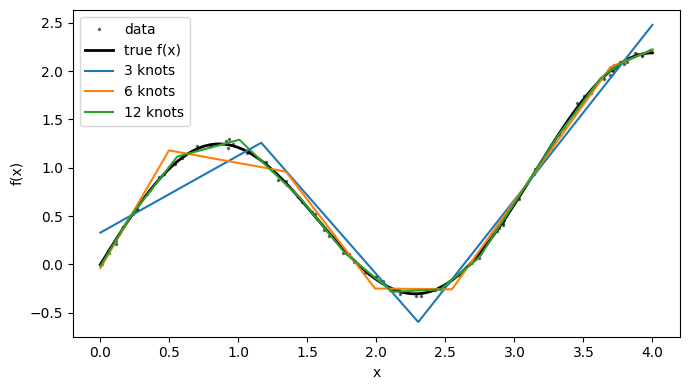

In [3]:
grid = np.linspace(0, 4, 801)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, y, "k.", ms=3, alpha=0.5, label="data")
ax.plot(grid, f_true(grid), "k-", lw=2, label="true f(x)")
for k, model in models.items():
    ax.plot(grid, np.asarray(model.predict(grid.reshape(-1, 1))), label=f"{k} knots")
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.legend()
plt.tight_layout()
plt.show()

The fitted expression is an ordinary JAXSR expression, so `to_sympy()`,
`to_callable()` and `save()` all work. Before embedding it, we check that every
selected term is MILP-representable. An empty list means the embedding is a
pure MILP.

In [4]:
model = models[12]
print(model.expression_)
print("non-MILP terms:", milp_incompatible_terms(model))

y = 2.01*max(0,x-2.74485) + 1.093*max(0,2.46303-x) - 1.431*max(0,0.557208-x) - 0.9646*max(0,2.74485-x) - 0.8621*max(0,x-3.62335) - 1.757*max(0,1.00688-x) + 1.241*max(0,2.11603-x) + 0.5945*max(0,x-1.76882) - 0.394*max(0,x-1.44919) - 0.5631*max(0,0.212114-x) - 0.275*max(0,x-3.31162) - 0.4449*max(0,x-3.76412)
non-MILP terms: []


## 2. Embedding in Pyomo and minimizing

`model.to_pyomo()` returns a Pyomo `ConcreteModel` (or fills a `Block` you pass
in). The input and output variables are available as `jaxsr_inputs` and
`jaxsr_output`. Each hinge whose knot lies inside the input bounds becomes one
continuous variable, one binary and four linear constraints (big-M), with the
big-M constants computed from the bounds.

In [5]:
def minimize_pyomo(model, **kwargs):
    blk = model.to_pyomo(**kwargs)
    blk.obj = pyo.Objective(expr=blk.jaxsr_output, sense=pyo.minimize)
    highs.solve(blk)
    x_opt = {name: pyo.value(v) for name, v in blk.jaxsr_inputs.items()}
    return x_opt, pyo.value(blk.obj), blk


print(f"{'knots':>5} {'x*':>8} {'surrogate f(x*)':>16} {'true f(x*)':>11} {'binaries':>9}")
for k, m in models.items():
    x_opt, f_opt, blk = minimize_pyomo(m)
    print(f"{k:5d} {x_opt['x']:8.4f} {f_opt:16.4f} {f_true(x_opt['x']):11.4f} {len(blk.binaries):9d}")

x_best = grid[np.argmin(f_true(grid))]
print(f"\ntrue minimum: x = {x_best:.4f}, f = {f_true(x_best):.4f}")

knots       x*  surrogate f(x*)  true f(x*)  binaries


    3   2.3037          -0.5968     -0.3034         3


    6   2.5478          -0.2575     -0.1631         7


   12   2.1160          -0.2838     -0.2520        12

true minimum: x = 2.2800, f = -0.3044


Two things are worth noticing.

First, the MILP solver found the **global** minimum of each surrogate. None of
them got stuck at the local minimum at $x = 0$, which a gradient-based optimizer
started on the left would have returned. That guarantee comes from the MILP
formulation, not from a good starting guess.

Second, the global minimum of the *surrogate* is not the minimum of the *true
function*. The 3-knot model is the extreme case: it predicts a value far below
anything $f$ actually reaches, because a kink placed in the wrong spot
overshoots. An optimizer goes straight to wherever the surrogate is most
optimistic, so surrogate error matters most exactly at the optimum. The answer
is to check the optimum against the real function and refine there.

## 3. Refine where the optimizer looks

A simple refinement loop:

1. Solve the MILP for the current surrogate's optimum $x^*$.
2. Evaluate the true function at $x^*$ and at a few points around it, within a
   radius that shrinks each round.
3. Add a pair of knots just either side of $x^*$, so the fit can bend there,
   and refit.

Here we pass the knots explicitly with `add_hinges(knots={"x": [...]})`. We
start from 6 knots at data quantiles, the same as the 6-knot model above.

In [6]:
X_ref, y_ref = X.copy(), y.copy()
knots = list(np.quantile(x, np.arange(1, 7) / 7))
history = []
for it in range(6):
    library = (
        BasisLibrary(n_features=1, feature_names=["x"], feature_bounds=[(0.0, 4.0)])
        .add_constant()
        .add_linear()
        .add_hinges(knots={"x": knots})
    )
    m = SymbolicRegressor(basis_library=library, max_terms=14, information_criterion="bic")
    m.fit(X_ref, y_ref)
    x_opt, f_opt, _ = minimize_pyomo(m)
    xs = x_opt["x"]
    history.append((it, xs, f_opt, f_true(xs), len(m.selected_features_)))

    # Sample the truth around x* (shrinking radius), and add knots either side of it.
    r = 0.3 / (it + 1)
    new_x = np.clip(np.append(xs + np.linspace(-r, r, 6), xs), 0, 4)
    X_ref = np.vstack([X_ref, new_x.reshape(-1, 1)])
    y_ref = np.append(y_ref, f_true(new_x) + rng.normal(0, 0.02, new_x.size))
    knots += [xs - r / 2, xs + r / 2]

print(f"{'iter':>4} {'x*':>8} {'surrogate':>10} {'true f(x*)':>11} {'terms':>6}")
for it, xs, fs, ft, nt in history:
    print(f"{it:4d} {xs:8.4f} {fs:10.4f} {ft:11.4f} {nt:6d}")
print(f"\ntrue minimum: x = {x_best:.4f}, f = {f_true(x_best):.4f}")

iter       x*  surrogate  true f(x*)  terms
   0   2.5478    -0.2575     -0.1631      8
   1   2.3979    -0.3130     -0.2772      7
   2   2.3228    -0.3453     -0.3009      7
   3   2.3228    -0.3375     -0.3009      7
   4   2.2854    -0.3183     -0.3044      8
   5   2.2729    -0.3181     -0.3043      9

true minimum: x = 2.2800, f = -0.3044


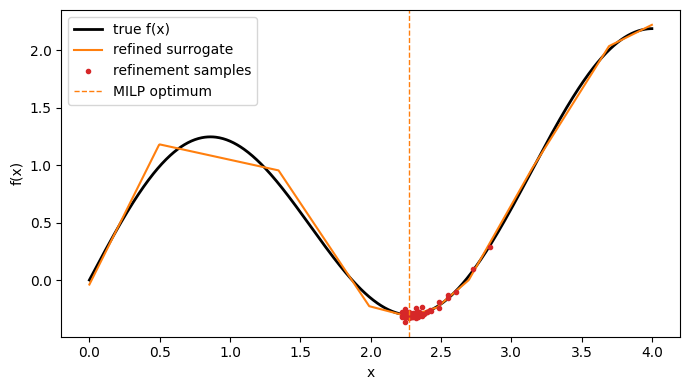

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(grid, f_true(grid), "k-", lw=2, label="true f(x)")
ax.plot(grid, np.asarray(m.predict(grid.reshape(-1, 1))), "C1-", label="refined surrogate")
ax.plot(X_ref[len(x):, 0], y_ref[len(x):], "C3.", label="refinement samples")
ax.axvline(history[-1][1], color="C1", ls="--", lw=1, label="MILP optimum")
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.legend()
plt.tight_layout()
plt.show()

Within a few rounds the MILP optimum moves to the true minimizer, and the true
value there matches the true minimum to three decimals. The surrogate's own
prediction at $x^*$ stays slightly optimistic, at about the noise level of the
data. That is expected, because the optimizer always picks the point where the
fitted model is lowest.

The plot also shows that the refined surrogate is still coarse away from $x^*$,
around the local maximum near $x = 1$. That is fine: refinement spends samples
only where the answer depends on them.

This is the standard pattern for optimizing over a surrogate: the MILP gives a
certified optimum *of the model*, and new samples make the model accurate at
that optimum. The same loop works with real experiments or an expensive
simulator in place of `f_true`.

## 4. Two inputs

Hinges act on one feature at a time, so a hinge model is a sum of 1-D
piecewise-linear functions, one per input (plus categorical terms, shown in
section 6). That suits responses that are roughly additive in their inputs. Here
is one:

$$f(x_1, x_2) = \tfrac12 (x_1 - 1)^2 (x_1 - 3)^2 + 0.4 x_1 + |x_2 - 2| + 0.3 x_2,$$

which is nonconvex in $x_1$ (two valleys) and has a kink in $x_2$.

If your response has strong interactions such as $x_1 x_2$, an additive hinge
model will fit it poorly. You can then add `add_interactions()` and embed with
`allow_nonlinear=True`, which turns the problem into an MINLP for a solver such
as discopt.

In [8]:
def f2_true(x1, x2):
    return 0.5 * (x1 - 1) ** 2 * (x1 - 3) ** 2 + 0.4 * x1 + np.abs(x2 - 2) + 0.3 * x2


X2 = rng.uniform(0, 4, size=(400, 2))
y2 = f2_true(X2[:, 0], X2[:, 1]) + rng.normal(0, 0.02, 400)

library2 = (
    BasisLibrary(n_features=2, feature_names=["x1", "x2"], feature_bounds=[(0, 4), (0, 4)])
    .add_constant()
    .add_linear()
    .add_hinges(X=X2, n_knots=10)
)
model2 = SymbolicRegressor(basis_library=library2, max_terms=14, information_criterion="bic")
model2.fit(X2, y2)
print(f"{len(model2.selected_features_)} terms, R2 = {model2.metrics_['r2']:.4f}")
print("non-MILP terms:", milp_incompatible_terms(model2))

14 terms, R2 = 0.9947
non-MILP terms: []


MILP optimum: {'x1': 0.779284, 'x2': 2.02693} surrogate = 1.0318, true = 1.0668
true optimum on grid: x1 = 0.92, x2 = 2.00, f = 0.9818


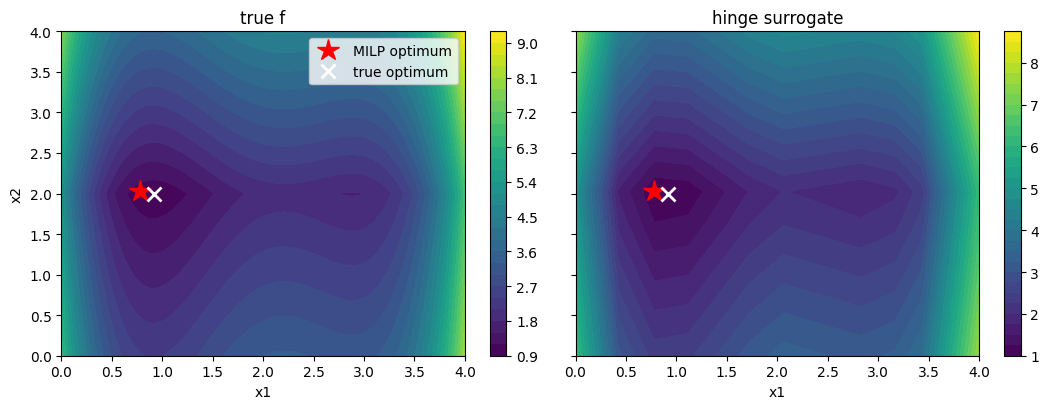

In [9]:
x_opt2, f_opt2, blk2 = minimize_pyomo(model2)
print("MILP optimum:", x_opt2, f"surrogate = {f_opt2:.4f}, true = {f2_true(**x_opt2):.4f}")

g = np.linspace(0, 4, 201)
A, B = np.meshgrid(g, g)
F_true = f2_true(A, B)
F_sur = np.asarray(model2.predict(np.column_stack([A.ravel(), B.ravel()]))).reshape(A.shape)
i_true = np.argmin(F_true)
print(f"true optimum on grid: x1 = {A.flat[i_true]:.2f}, x2 = {B.flat[i_true]:.2f}, "
      f"f = {F_true.flat[i_true]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, F, title in zip(axes, (F_true, F_sur), ("true f", "hinge surrogate"), strict=True):
    cs = ax.contourf(A, B, F, levels=30, cmap="viridis")
    ax.plot(x_opt2["x1"], x_opt2["x2"], "r*", ms=16, label="MILP optimum")
    ax.plot(A.flat[i_true], B.flat[i_true], "wx", ms=10, mew=2, label="true optimum")
    ax.set_title(title)
    ax.set_xlabel("x1")
    fig.colorbar(cs, ax=ax)
axes[0].set_ylabel("x2")
axes[0].legend(loc="upper right")
plt.tight_layout()
plt.show()

The surrogate reproduces both valleys in $x_1$ and the kink in $x_2$, and the
MILP lands in the correct (left) valley. The small offset from the true optimum
is surrogate error, which section 3's refinement loop would close.

### Fewer binaries with `output_sense`

Each hinge needs one binary in the exact formulation. When we only ever
*minimize* the output, a hinge with a **positive** coefficient is convex in the
right direction: the solver already pushes it down onto $\max(0, x - k)$, so it
needs no binary. Passing `output_sense="min"` drops those binaries. We compare
the two formulations on a larger model with 20 knots per feature.

In [10]:
library3 = (
    BasisLibrary(n_features=2, feature_names=["x1", "x2"], feature_bounds=[(0, 4), (0, 4)])
    .add_constant()
    .add_linear()
    .add_hinges(X=X2, n_knots=20)
)
model3 = SymbolicRegressor(basis_library=library3, max_terms=25, information_criterion="bic")
model3.fit(X2, y2)
print(f"{len(model3.selected_features_)} terms")

print(f"{'output_sense':>12} {'binaries':>9} {'objective':>10} {'time (s)':>9}")
for sense in (None, "min"):
    t0 = time.perf_counter()
    x_opt3, f_opt3, blk3 = minimize_pyomo(model3, output_sense=sense)
    dt = time.perf_counter() - t0
    print(f"{str(sense):>12} {len(blk3.binaries):9d} {f_opt3:10.5f} {dt:9.3f}")

24 terms
output_sense  binaries  objective  time (s)


        None        23    0.99754     0.017


         min         7    0.99754     0.032


Both formulations give the same optimum, and the relaxed one has fewer
binaries. At this size HiGHS solves either in a fraction of a second, but the
saving grows with the number of hinges and with embedded models that sit inside
bigger problems.

**Use `output_sense` only when it is valid.** It is correct only if the output
appears solely in a minimized objective (for `"min"`) or solely in a maximized
one (for `"max"`). If the output also appears in a constraint such as
`cost >= 2`, the relaxed hinges can float upward, and the answer is wrong. The
default, `output_sense=None`, is exact in any problem.

## 5. A design problem with discrete decisions, in Pyomo and discopt

Real problems embed the surrogate among other variables and constraints. We
treat `model2` as the operating cost of a unit and add the following:

- an operating constraint $x_1 + x_2 \ge 4$,
- an optional upgrade, a binary $u$ with fixed cost 0.3, that relaxes the
  constraint to $x_1 + x_2 \ge 3$.

The solver has to trade off the upgrade cost against cheaper operation. We pass
our own variables through `inputs=` and `output=`, and the embedding links them
with equality constraints.

In [11]:
m = pyo.ConcreteModel()
m.x1 = pyo.Var(bounds=(0, 4))
m.x2 = pyo.Var(bounds=(0, 4))
m.cost = pyo.Var()
m.u = pyo.Var(within=pyo.Binary)
m.sr = pyo.Block()
model2.to_pyomo(m.sr, inputs={"x1": m.x1, "x2": m.x2}, output=m.cost)

m.spec = pyo.Constraint(expr=m.x1 + m.x2 >= 4 - m.u)
m.obj = pyo.Objective(expr=m.cost + 0.3 * m.u, sense=pyo.minimize)
highs.solve(m)

print(f"Pyomo/HiGHS: x1 = {pyo.value(m.x1):.4f}, x2 = {pyo.value(m.x2):.4f}, "
      f"upgrade = {round(pyo.value(m.u))}, total = {pyo.value(m.obj):.5f}")

Pyomo/HiGHS: x1 = 0.9731, x2 = 2.0269, upgrade = 1, total = 1.36210


The same model in discopt. `to_discopt` returns a `DiscoptEmbedding` whose
`inputs` and `output` are discopt variables, so we can write constraints on them
directly. Every variable it creates is named with a `prefix` (default
`"jaxsr"`), which lets several surrogates live in one model.

In [12]:
dm_model = discopt.Model("design")
emb = model2.to_discopt(dm_model)
u = dm_model.binary("upgrade")
dm_model.subject_to(emb.inputs["x1"] + emb.inputs["x2"] >= 4 - u)
dm_model.minimize(emb.output + 0.3 * u)
result = dm_model.solve()

print(f"discopt: status = {result.status}, total = {result.objective:.5f}")
print(f"agrees with Pyomo: {abs(result.objective - pyo.value(m.obj)) < 1e-5}")

discopt: status = optimal, total = 1.36210


agrees with Pyomo: True


## 6. Choosing a catalyst: categorical inputs

Categorical inputs become **one-hot binaries** in the embedding, so a "which
option?" decision becomes part of the MILP. Here the yield of a reaction depends
on temperature $T \in [300, 400]$ K and which of three catalysts is used. Each
catalyst has its own baseline and temperature slope, and every catalyst loses
yield above about 370 K (a hinge). The catalysts also have different costs.

In [13]:
catalysts = ["Pt", "Pd", "Ni"]
base = np.array([0.60, 0.55, 0.30])
slope = np.array([0.10, 0.25, 0.45])          # yield gain per 100 K
cat_cost = {"Pt": 0.20, "Pd": 0.10, "Ni": 0.0}


def yield_true(c, T):
    t = (T - 300) / 100
    return base[c] + slope[c] * t - 1.2 * np.maximum(0, T - 370) / 100


c = rng.integers(0, 3, 300)
T = rng.uniform(300, 400, 300)
Xc = np.column_stack([c, T]).astype(float)
yc = yield_true(c, T) + rng.normal(0, 0.005, 300)

library_c = (
    BasisLibrary(
        n_features=2,
        feature_names=["catalyst", "T"],
        feature_types=["categorical", "continuous"],
        categories={0: catalysts},
        feature_bounds=[(0, 2), (300, 400)],
    )
    .add_constant()
    .add_linear()
    .add_categorical_indicators()
    .add_categorical_interactions()
    .add_hinges(X=Xc, n_knots=9)
)
model_c = SymbolicRegressor(basis_library=library_c, max_terms=8, information_criterion="bic")
model_c.fit(Xc, yc)
print(model_c.expression_)
print("non-MILP terms:", milp_incompatible_terms(model_c))

y = 0.7191 - 1.124*I(catalyst=Ni) - 2.9768e-05*max(0,T-380.064) + 0.002851*I(catalyst=Ni)*T + 0.0006223*max(0,343.177-T) - 0.01021*max(0,T-366.382) - 0.002236*max(0,380.064-T) + 6.0966e-05*I(catalyst=Pd)*T
non-MILP terms: []


We maximize yield minus catalyst cost. `jaxsr_onehot[("catalyst", name)]` is the
binary that is 1 when that catalyst is chosen, so the cost term is just a linear
expression in those binaries.

In [14]:
blk = model_c.to_pyomo()
blk.profit = pyo.Objective(
    expr=blk.jaxsr_output - sum(cat_cost[n] * blk.jaxsr_onehot[("catalyst", n)] for n in catalysts),
    sense=pyo.maximize,
)
highs.solve(blk)
chosen = [n for n in catalysts if pyo.value(blk.jaxsr_onehot[("catalyst", n)]) > 0.5][0]
T_opt = pyo.value(blk.jaxsr_inputs["T"])
print(f"MILP: catalyst = {chosen}, T = {T_opt:.1f} K, profit = {pyo.value(blk.profit):.4f}")

# Brute-force check on the surrogate: every catalyst on a fine T grid.
Tg = np.linspace(300, 400, 2001)
for k, name in enumerate(catalysts):
    pred = np.asarray(model_c.predict(np.column_stack([np.full_like(Tg, k), Tg])))
    profit = pred - cat_cost[name]
    print(f"  {name}: best T = {Tg[profit.argmax()]:.1f} K, profit = {profit.max():.4f}")

MILP: catalyst = Pd, T = 366.4 K, profit = 0.6108
  Pt: best T = 366.4 K, profit = 0.4884
  Pd: best T = 366.4 K, profit = 0.6108
  Ni: best T = 366.4 K, profit = 0.6088


The MILP picks the same catalyst and temperature as brute-force enumeration of
the surrogate. With three catalysts and one temperature, enumeration is cheap.
With several categorical decisions and many continuous inputs it is not, and
that is where the MILP formulation pays off.

## Summary

The workflow is:

1. **Fit with a piecewise-linear library.** Use `add_constant`, `add_linear`,
   `add_hinges` and, if you need them, `add_transcendental(["abs"])` and the
   categorical builders. Place knots where the response bends, or let data
   quantiles place them.
2. **Check** that `milp_incompatible_terms(model) == []`.
3. **Embed** with `model.to_pyomo(block, inputs=..., output=...)` or
   `model.to_discopt(dm_model, ...)`, and add your own objective and
   constraints.
4. **Verify the optimum against the real system and refine there.** The MILP
   certifies the surrogate's optimum, not the truth's.

Input bounds come from `bounds=`, then `feature_bounds`, then the training data,
and the embedding enforces them so the optimizer cannot exploit extrapolation.
See the [MIP embedding guide](../guides/mip-embedding.md) for the formulations
and every option, including `allow_nonlinear=True` for MINLP surrogates.